# RuteStrip Dataset Exploration

Notebook ini memperlihatkan fungsi penting dari dataset **RuteStrip Indonesian Hiking Routes GPX Features and SBERT Embeddings**.

Yang akan dicoba:

- Membaca dataset rute dan embedding.
- Melihat statistik fitur GPX: jarak, elevasi, durasi, grade, dan difficulty.
- Membuat visualisasi sederhana.
- Melakukan pencarian semantik/rekomendasi rute menggunakan cosine similarity antar embedding.
- Membuat baseline klasifikasi difficulty dari fitur numerik.

## Dokumentasi Fungsi Notebook

- `find_dataset_dir()`: mencari lokasi dataset secara fleksibel. Di Kaggle fungsi ini menelusuri `/kaggle/input`, sedangkan di lokal memakai folder notebook saat file CSV tersedia di sana.
- `recommend_similar_routes(route_name_keyword, top_k=5)`: mencari satu rute berdasarkan kata kunci nama, mengambil embedding rute tersebut, lalu menghitung cosine similarity terhadap rute lain untuk menghasilkan daftar rute paling mirip.
- Blok visualisasi statistik: membaca kolom GPX seperti jarak, elevasi, durasi, grade, dan difficulty untuk memahami distribusi dataset.
- Blok baseline klasifikasi: memakai fitur numerik GPX untuk menguji apakah difficulty bisa diprediksi secara sederhana dengan Random Forest dan cross-validation.
- Blok embedding inspection: mengecek dimensi embedding dan contoh fitur agar dataset siap dipakai untuk semantic search, clustering, atau eksperimen rekomendasi.

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_colwidth', 140)

## 2. Load Dataset

Di Kaggle, dataset biasanya tersedia di folder `/kaggle/input/<dataset-slug>/`. Cell berikut dibuat fleksibel agar bisa berjalan di Kaggle maupun lokal.

In [2]:
def find_dataset_dir():
    kaggle_input = '/kaggle/input'
    if os.path.exists(kaggle_input):
        for root, dirs, files in os.walk(kaggle_input):
            if 'rutestrip_hiking_routes.csv' in files:
                return root
    return '.'

DATA_DIR = find_dataset_dir()
routes_path = os.path.join(DATA_DIR, 'rutestrip_hiking_routes.csv')
embeddings_path = os.path.join(DATA_DIR, 'rutestrip_hiking_route_embeddings.csv')

routes = pd.read_csv(routes_path)
embeddings = pd.read_csv(embeddings_path)

print('Dataset directory:', DATA_DIR)
print('Routes shape:', routes.shape)
print('Embeddings shape:', embeddings.shape)

Dataset directory: .
Routes shape: (39, 17)
Embeddings shape: (39, 386)


In [3]:
routes.head()

,route_id,route_name,original_name,mountain,province,distance_km,elevation_gain_m,naismith_duration_hour,average_grade_pct,min_elevation_m,max_elevation_m,difficulty,total_trackpoints,manual_description,narrative_text,embedding_model,embedding_dimension
0,1,Argopuro - Bremi Baderan,1766063593 6943Fde95C187 Argopuro - Bremi Baderan,Argopuro,Jawa Timur,53.83,3243,16.17,6.02,773,3058,sedang,492,Trek panjang multi-hari dengan savana luas dan hutan lebat. Jalur menantang untuk pendaki berpengalaman.,Trek panjang multi-hari dengan savana luas dan hutan lebat. Jalur menantang untuk pendaki berpengalaman. Jalur pendakian dengan jarak pa...,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384
1,2,Agung - Besakih,1766063653 6943Fe257Db87 Agung - Besakih,Agung,Bali,76.05,577,16.17,0.76,9,3033,mudah,5282,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda.,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda. Jalur pendakian dengan jarak panjan...,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384
2,3,Agung - Pura Pasar Agung,1766063671 6943Fe37D1Cb6 Agung - Pura Pasar Agung,Agung,Bali,8.91,0,1.78,0.00,0,0,mudah,9842,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda.,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda. Jalur pendakian dengan jarak panjan...,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384
3,4,Anak Krakatau,1766063689 6943Fe49E4Fab Anak Krakatau,Anak Krakatau,Lampung,3.85,469,1.55,12.18,4,324,sulit,550,Gunung vulkanik dengan trekking singkat menuju puncak. Pemandangan laut dan pulau-pulau sekitar.,Gunung vulkanik dengan trekking singkat menuju puncak. Pemandangan laut dan pulau-pulau sekitar. Jalur pendakian dengan jarak sedang sek...,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384
4,5,Argopuro - Bremi Baderan,1766063707 6943Fe5B08731 Argopuro - Bremi Baderan,Argopuro,Jawa Timur,53.83,3243,16.17,6.02,773,3058,sedang,492,Trek panjang multi-hari dengan savana luas dan hutan lebat. Jalur menantang untuk pendaki berpengalaman.,Trek panjang multi-hari dengan savana luas dan hutan lebat. Jalur menantang untuk pendaki berpengalaman. Jalur pendakian dengan jarak pa...,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384


## 3. Ringkasan Dataset

In [4]:
summary = {
    'total_routes': len(routes),
    'total_mountains': routes['mountain'].nunique(),
    'total_provinces': routes['province'].nunique(),
    'min_distance_km': routes['distance_km'].min(),
    'max_distance_km': routes['distance_km'].max(),
    'avg_distance_km': routes['distance_km'].mean(),
    'avg_elevation_gain_m': routes['elevation_gain_m'].mean(),
    'avg_duration_hour': routes['naismith_duration_hour'].mean(),
}
pd.Series(summary)

total_routes              39.000000
total_mountains           16.000000
total_provinces            6.000000
min_distance_km            3.850000
max_distance_km          114.510000
avg_distance_km           25.821795
avg_elevation_gain_m    2760.538462
avg_duration_hour          9.765385
dtype: float64

In [5]:
routes['difficulty'].value_counts()

difficulty
sulit           22
sangat sulit     8
sedang           6
mudah            3
Name: count, dtype: int64

## 4. Visualisasi Fitur GPX

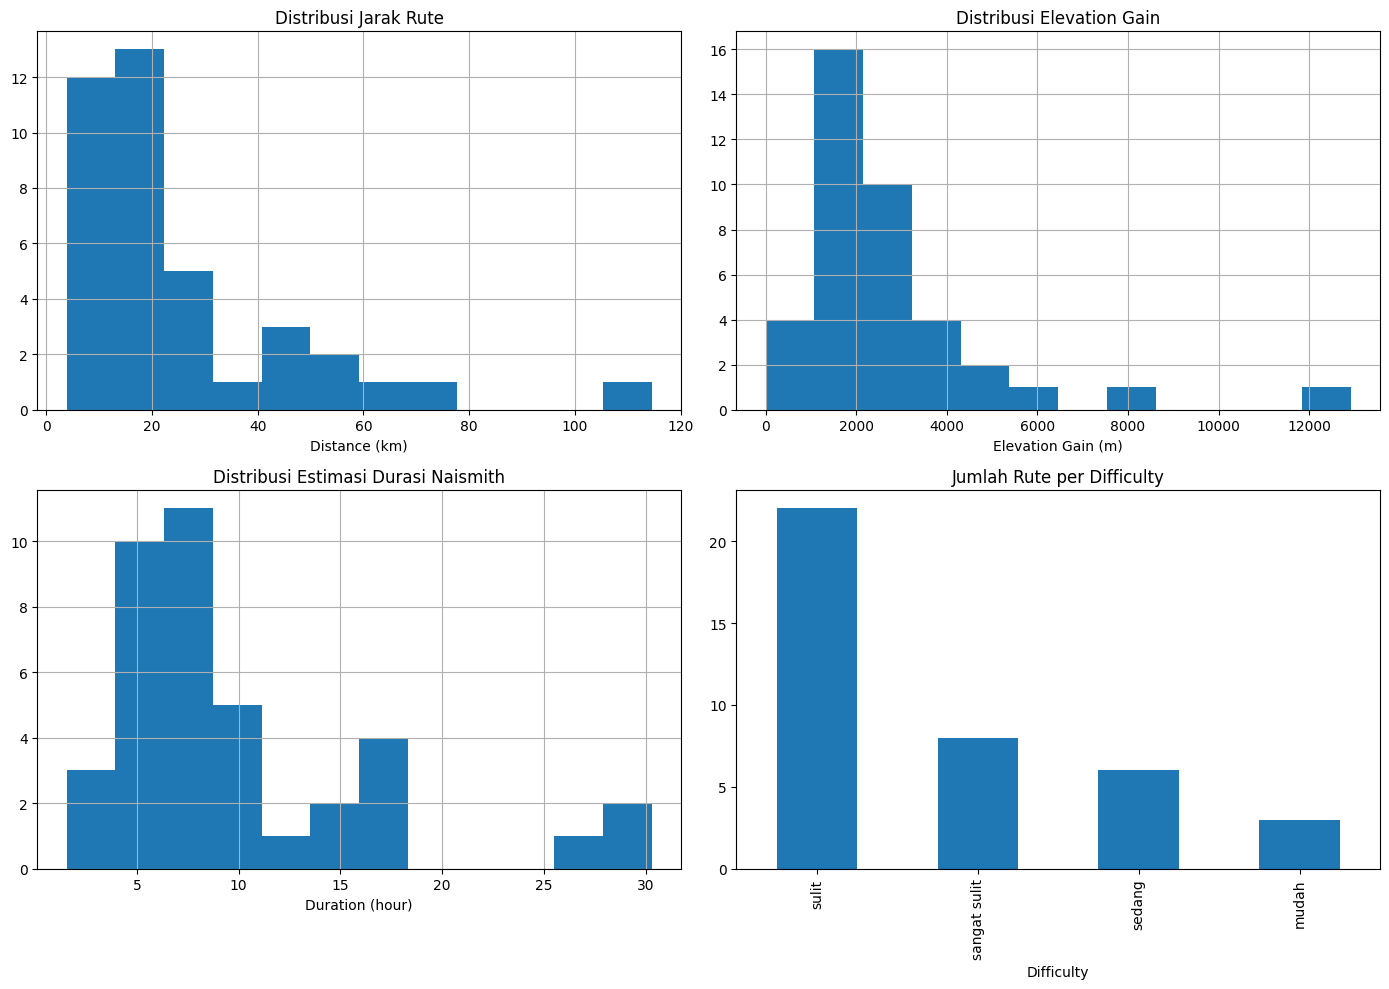

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

routes['distance_km'].hist(ax=axes[0, 0], bins=12)
axes[0, 0].set_title('Distribusi Jarak Rute')
axes[0, 0].set_xlabel('Distance (km)')

routes['elevation_gain_m'].hist(ax=axes[0, 1], bins=12)
axes[0, 1].set_title('Distribusi Elevation Gain')
axes[0, 1].set_xlabel('Elevation Gain (m)')

routes['naismith_duration_hour'].hist(ax=axes[1, 0], bins=12)
axes[1, 0].set_title('Distribusi Estimasi Durasi Naismith')
axes[1, 0].set_xlabel('Duration (hour)')

routes['difficulty'].value_counts().plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Jumlah Rute per Difficulty')
axes[1, 1].set_xlabel('Difficulty')

plt.tight_layout()

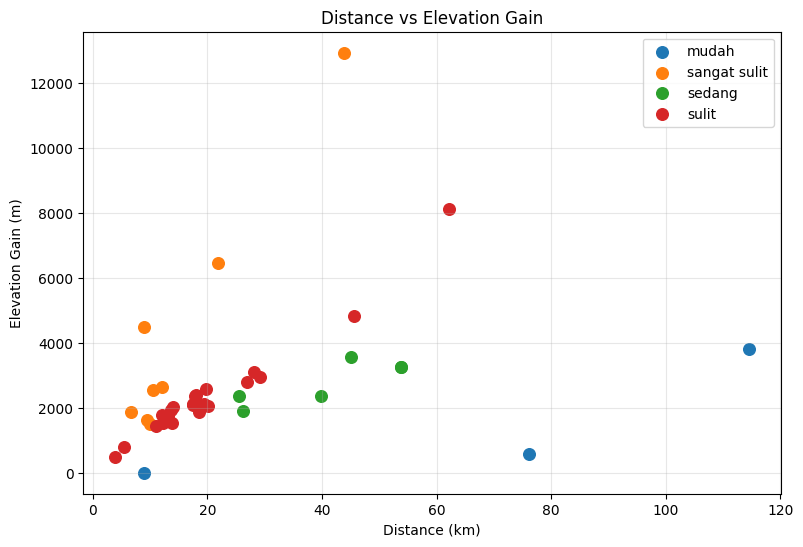

In [7]:
plt.figure(figsize=(9, 6))
for difficulty, group in routes.groupby('difficulty'):
    plt.scatter(group['distance_km'], group['elevation_gain_m'], label=difficulty, s=70)

plt.title('Distance vs Elevation Gain')
plt.xlabel('Distance (km)')
plt.ylabel('Elevation Gain (m)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Rute Ekstrem dan Rekomendasi Berdasarkan Fitur

Bagian ini menunjukkan contoh insight langsung dari fitur GPX yang sudah diproses.

In [8]:
cols = ['route_name', 'mountain', 'province', 'distance_km', 'elevation_gain_m', 'naismith_duration_hour', 'average_grade_pct', 'difficulty']

print('Rute terpanjang:')
display(routes.sort_values('distance_km', ascending=False)[cols].head(5))

print('Rute dengan elevation gain tertinggi:')
display(routes.sort_values('elevation_gain_m', ascending=False)[cols].head(5))

print('Rute paling singkat berdasarkan Naismith:')
display(routes.sort_values('naismith_duration_hour')[cols].head(5))

Rute terpanjang:


,route_name,mountain,province,distance_km,elevation_gain_m,naismith_duration_hour,average_grade_pct,difficulty
18,Ijen - Sempol,Ijen,Jawa Timur,114.51,3813,29.26,3.33,mudah
1,Agung - Besakih,Agung,Bali,76.05,577,16.17,0.76,mudah
13,Gede-Pangrango Semua Jalur,Gede-Pangrango,Jawa Barat,62.10,8120,25.95,13.08,sulit
0,Argopuro - Bremi Baderan,Argopuro,Jawa Timur,53.83,3243,16.17,6.02,sedang
4,Argopuro - Bremi Baderan,Argopuro,Jawa Timur,53.83,3243,16.17,6.02,sedang


Rute dengan elevation gain tertinggi:


,route_name,mountain,province,distance_km,elevation_gain_m,naismith_duration_hour,average_grade_pct,difficulty
11,Ciremai - Cibuluh - Linggarjati,Ciremai,Jawa Barat,43.77,12919,30.29,29.52,sangat sulit
13,Gede-Pangrango Semua Jalur,Gede-Pangrango,Jawa Barat,62.10,8120,25.95,13.08,sulit
10,Ciremai - Apuy Linggarjati,Ciremai,Jawa Barat,21.89,6459,15.14,29.52,sangat sulit
9,Cikuray - Pemancar,Cikuray,NaN,45.59,4810,17.13,10.55,sulit
7,Butak - Sirah Kencong,Butak,Jawa Timur,8.99,4485,9.27,49.92,sangat sulit


Rute paling singkat berdasarkan Naismith:


,route_name,mountain,province,distance_km,elevation_gain_m,naismith_duration_hour,average_grade_pct,difficulty
3,Anak Krakatau,Anak Krakatau,Lampung,3.85,469,1.55,12.18,sulit
2,Agung - Pura Pasar Agung,Agung,Bali,8.91,0,1.78,0.00,mudah
15,Guntur Masigit - Cibeureum,Guntur,NaN,5.46,799,2.42,14.66,sulit
34,Mt. Slamet Via Dipajaya,Slamet,Jawa Tengah,6.61,1870,4.44,28.31,sangat sulit
16,Guntur Masigit - Tanjung Karya,Guntur,NaN,9.93,1509,4.50,15.20,sangat sulit


## 6. Semantic Similarity dan Route Recommendation

Dataset menyediakan embedding SBERT untuk tiap rute. Kita bisa memakai cosine similarity untuk mencari rute yang mirip secara semantik berdasarkan `narrative_text`.

In [9]:
embedding_cols = [col for col in embeddings.columns if col.startswith('embedding_')]
embedding_matrix = embeddings[embedding_cols].to_numpy(dtype=float)

similarity_matrix = cosine_similarity(embedding_matrix)
print('Embedding matrix:', embedding_matrix.shape)
print('Similarity matrix:', similarity_matrix.shape)

Embedding matrix: (39, 384)
Similarity matrix: (39, 39)


In [10]:
def recommend_similar_routes(route_name_keyword, top_k=5):
    matches = routes[routes['route_name'].str.contains(route_name_keyword, case=False, na=False)]
    if matches.empty:
        raise ValueError(f'No route found for keyword: {route_name_keyword}')

    selected = matches.iloc[0]
    route_id = selected['route_id']
    idx = embeddings.index[embeddings['route_id'] == route_id][0]

    scores = similarity_matrix[idx].copy()
    scores[idx] = -1
    top_indices = np.argsort(scores)[::-1][:top_k]

    result = routes.set_index('route_id').loc[embeddings.iloc[top_indices]['route_id']].reset_index()
    result['similarity_score'] = scores[top_indices]

    print('Selected route:')
    display(selected[cols])
    return result[cols + ['similarity_score']]

recommend_similar_routes('Argopuro', top_k=5)

Selected route:


route_name                Argopuro - Bremi Baderan
mountain                                  Argopuro
province                                Jawa Timur
distance_km                                  53.83
elevation_gain_m                              3243
naismith_duration_hour                       16.17
average_grade_pct                             6.02
difficulty                                  sedang
Name: 0, dtype: object

,route_name,mountain,province,distance_km,elevation_gain_m,naismith_duration_hour,average_grade_pct,difficulty,similarity_score
0,Argopuro - Bremi Baderan,Argopuro,Jawa Timur,53.83,3243,16.17,6.02,sedang,1.000000
1,Mt. Argopuro Baderan To Bremi,Argopuro,Jawa Timur,45.10,3566,14.96,7.91,sedang,0.998427
2,Mt. Arjuno Via Tretes,Arjuno,Jawa Timur,25.48,2355,9.02,9.25,sedang,0.962679
3,Mt. Sumbing Via Bowongso,Sumbing,Jawa Tengah,17.55,2079,6.98,11.85,sulit,0.936981
4,Cikuray - Pemancar,Cikuray,NaN,45.59,4810,17.13,10.55,sulit,0.935599


## 7. Query by Example

Karena dataset ini sudah berisi embedding rute, kita bisa mencari rute yang paling dekat dengan rute contoh. Untuk pencarian teks bebas seperti aplikasi RuteStrip, query perlu diubah dulu menjadi embedding menggunakan model SBERT yang sama.

In [11]:
example_routes = routes[['route_id', 'route_name', 'narrative_text']].head(3)
example_routes

,route_id,route_name,narrative_text
0,1,Argopuro - Bremi Baderan,Trek panjang multi-hari dengan savana luas dan hutan lebat. Jalur menantang untuk pendaki berpengalaman. Jalur pendakian dengan jarak pa...
1,2,Agung - Besakih,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda. Jalur pendakian dengan jarak panjan...
2,3,Agung - Pura Pasar Agung,Gunung suci Bali dengan pemandangan panorama pulau. Beberapa jalur dengan tingkat kesulitan berbeda. Jalur pendakian dengan jarak panjan...


Jika ingin menjalankan pencarian teks bebas di Kaggle, aktifkan internet dan install/load `sentence-transformers`, lalu encode query dengan model yang sama.

In [12]:
# Optional: free-text semantic search. Requires sentence-transformers and model availability.
# from sentence_transformers import SentenceTransformer
# model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
# query = 'jalur pendek untuk pemula dengan durasi singkat'
# query_embedding = model.encode([query])
# query_scores = cosine_similarity(query_embedding, embedding_matrix)[0]
# top_indices = np.argsort(query_scores)[::-1][:5]
# routes.iloc[top_indices][cols].assign(similarity_score=query_scores[top_indices])

## 8. Baseline Difficulty Classification

Contoh sederhana: gunakan fitur numerik GPX untuk memprediksi `difficulty`. Karena dataset kecil, hasil ini hanya baseline eksplorasi, bukan model final.

In [13]:
feature_cols = [
    'distance_km',
    'elevation_gain_m',
    'naismith_duration_hour',
    'average_grade_pct',
    'min_elevation_m',
    'max_elevation_m',
    'total_trackpoints',
]

df_model = routes.dropna(subset=feature_cols + ['difficulty']).copy()
X = df_model[feature_cols]
y = df_model['difficulty']

min_class_count = y.value_counts().min()
n_splits = max(2, min(3, min_class_count))

model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

print('CV folds:', n_splits)
print('Accuracy scores:', scores)
print('Mean accuracy:', scores.mean())

CV folds: 3
Accuracy scores: [0.92307692 0.76923077 0.69230769]
Mean accuracy: 0.794871794871795


In [14]:
model.fit(X, y)
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
importance

average_grade_pct         0.360366
distance_km               0.170171
min_elevation_m           0.117754
total_trackpoints         0.101237
max_elevation_m           0.093173
elevation_gain_m          0.079043
naismith_duration_hour    0.078256
dtype: float64

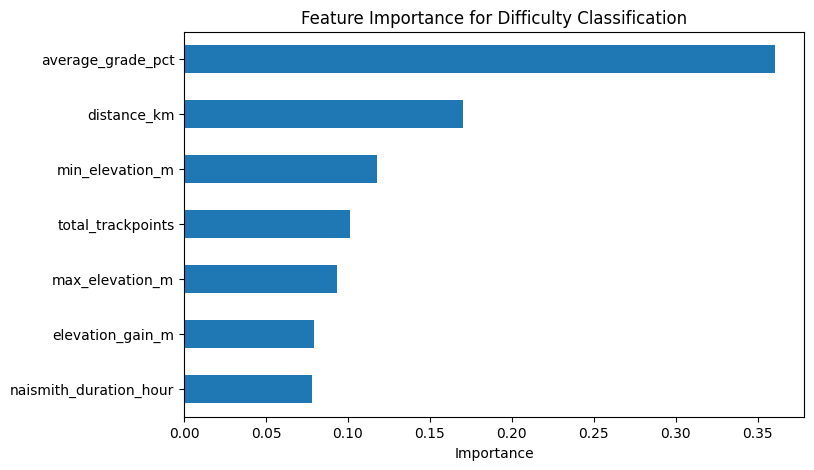

In [15]:
importance.sort_values().plot(kind='barh', figsize=(8, 5), title='Feature Importance for Difficulty Classification')
plt.xlabel('Importance')
plt.show()

## 9. Kesimpulan

Dataset ini cocok untuk beberapa eksperimen penting:

- Analisis statistik rute pendakian berbasis GPX.
- Rekomendasi rute mirip menggunakan embedding SBERT.
- Pencarian semantik rute pendakian dalam Bahasa Indonesia.
- Eksperimen klasifikasi difficulty dari fitur numerik.
- Eksplorasi hubungan jarak, elevasi, grade, dan estimasi durasi.